In [1]:
#we first import our generall systems
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#then we import our general models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay,  confusion_matrix,   accuracy_score,   precision_score,   recall_score,  f1_score,)

#last we load our csv
df = pd.read_csv("diabetes_binary_classification_data.csv")
df.head()
#Before viewing our head to get general information

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [2]:
#we check the datasets size, columns, and stored data types(int,str...)
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (253680, 22)
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non

***Learned information***

we have 253.680 rows, with 22 columns, and no missing values. we know that diabetes is our key variable, and that it is a dummy-variable( 0, 1) were o=no diabetes, 1=diabetes

In [3]:
#we count the respondents in each category class
class_summary = pd.DataFrame({
    "Count": df["Diabetes_binary"].value_counts().sort_index(),
    "Percentage": (
        df["Diabetes_binary"].value_counts(normalize=True)
        .sort_index() * 100
    )
})

class_summary

,Count,Percentage
Diabetes_binary,,
0.0,218334,86.066698
1.0,35346,13.933302


***Findings***

We can see that 218.334(86%) are healthy, and 35.346(14%) have diabetes

Q&A
 - ****What does one row represent****: Eacg riw reoresents one health-survey respondent. The dataset contains 253.680 respondents, and 22 cloumns. 1 key variable, and 21 input features
 - ****which column are we trying to predict****: Our target varibale iis diabetes:binary. 0 indicates a healhy respondent, 1 means pre-diabetes or diabetes. We use the other 21 features to predict this binary outcome
 - ****is the target balanced****: No, ca 86% of individuals are classes as "no diabetes". Respondents without diabetes therefore makes up a much larger portion of the dataset
 - ****What if we predicted "no diabetes" for everyone?****: In this case we would achieve aproximately 86% accuracy, due to most respondents beloning to class 0. However it would miss every respondent in class 1, giving a recall of 0 for that class. This indicates that accuracy alone is insufficient: a high accuracy can hdie a complete failure to identify the less common class

In [4]:
#next we want to separate the inputs from our target variable
X = df.drop(columns="Diabetes_binary")

# Target: the outcome we want to predict
y = df["Diabetes_binary"]

print("Number of input features:", X.shape[1])

Number of input features: 21


*Features in our dataset*


It is important to note that we have several different input categories in our dataset
- BMI is a numerical mesurment, a bmi of 30 equals a bmi of 30
- HighBP is a binary category where 0=no high bloodpressure, and 1=high blood pressure
- Age is a ordered categorical. f.ex a value of x indicates a age code, in this case a 9 would mean the age group 60-64 years

All columns are stored as numbers, but those numbers have different meanings

***Next we grup our inputs by type: chategorical, numerical, and binary.***

In [5]:
#Measurments and counts
Numerical_C = ["BMI", "MentHlth", "PhysHlth"]
Cat_C = ["Age", "Education", "Income", "GenHlth"]
Binary_C = [column for column in X.columns if column not in Numerical_C + Cat_C]

print("Numerical", Numerical_C)
print("categorical", Cat_C)
print("Binary", Binary_C)

Numerical ['BMI', 'MentHlth', 'PhysHlth']
categorical ['Age', 'Education', 'Income', 'GenHlth']
Binary ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']


***Does BMI differ between the two classes***

In [6]:
#We summarize BMI separatly for each target class
df.groupby("Diabetes_binary")["BMI"].describe()

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0.0,218334.0,27.805770,6.291414,12.0,24.0,27.0,31.0,98.0
1.0,35346.0,31.944011,7.363401,13.0,27.0,31.0,35.0,98.0


- we can read that BMI is ca 4 points higher in the individuals with diabetes
- the percentiles are also larger in individuals with diabetes

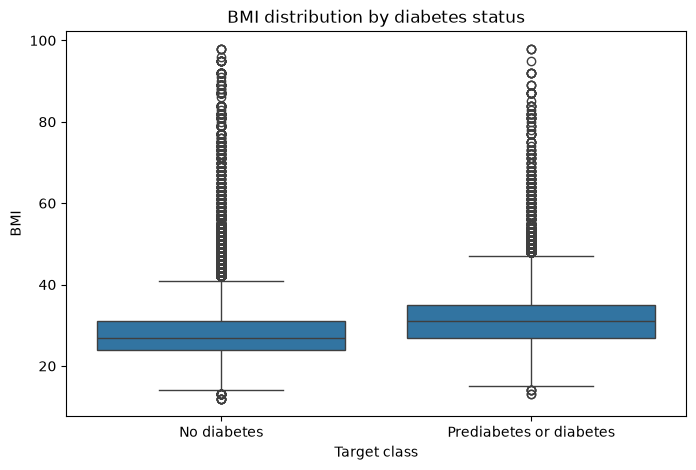

In [7]:
#Next we want to plot our findings
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Diabetes_binary", y="BMI",)

plt.xticks([0, 1], ["No diabetes", "Prediabetes or diabetes"])
plt.xlabel("Target class")
plt.ylabel("BMI")
plt.title("BMI distribution by diabetes status")
plt.show()

Respondents with prediabetes or diabetes have a higher median BMI than respondents without diabetes. However, the distributions overlap considerably, indicating that BMI alone cannot perfectly distinguish the two classes. The plot suggests an association between BMI and diabetes status in this dataset, but it does not establish that higher BMI causes diabetes.

***Next we want to explore physical health and mental health***
Both measure form, day by day for the last 30 days
- MentHlth meassures days where mental health was not good
- PhysHlth meassures days were physical health was not good

We now want to see: Do respondents in the two classes report different numbers of poor-health days?


Summary for MentHlth:


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0.0,218334.0,2.978034,7.111865,0.0,0.0,0.0,2.0,30.0
1.0,35346.0,4.461806,8.947717,0.0,0.0,0.0,3.0,30.0


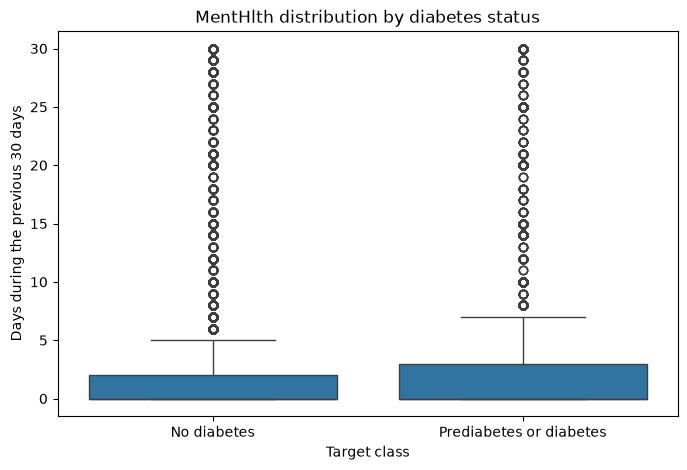


Summary for PhysHlth:


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0.0,218334.0,3.641082,8.064600,0.0,0.0,0.0,2.0,30.0
1.0,35346.0,7.954479,11.301491,0.0,0.0,1.0,15.0,30.0


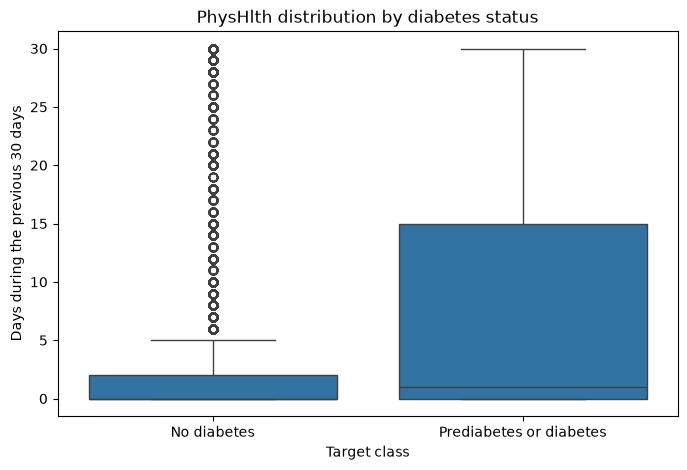

In [8]:
for feature in ["MentHlth", "PhysHlth"]:

    print(f"\nSummary for {feature}:")
    display(df.groupby("Diabetes_binary")[feature].describe())

    plt.figure(figsize=(8, 5))

    sns.boxplot( data=df, x="Diabetes_binary", y=feature)

    plt.xticks([0, 1], ["No diabetes", "Prediabetes or diabetes"])

    plt.xlabel("Target class")
    plt.ylabel("Days during the previous 30 days")
    plt.title(f"{feature} distribution by diabetes status")
    plt.show()

From these readings we can see that a mean individual with diabetes or pre diabetes records higher numbers both in days with poor mental health, and physical health

We can see that for mental health the nubmers and distribtuion is quite close, meanwhile for physical health the deviency is larger. We can also see that the 75% percentile for physicall health is substantially larger for individuals with diabetes or pre diabetes

***High blood preassure***

lastly we want to have a look at high blood preassure.

,Respondents,Class_1_count,Class_1_percent
HighBP,,,
0.0,144851,8742.0,6.035167
1.0,108829,26604.0,24.445690


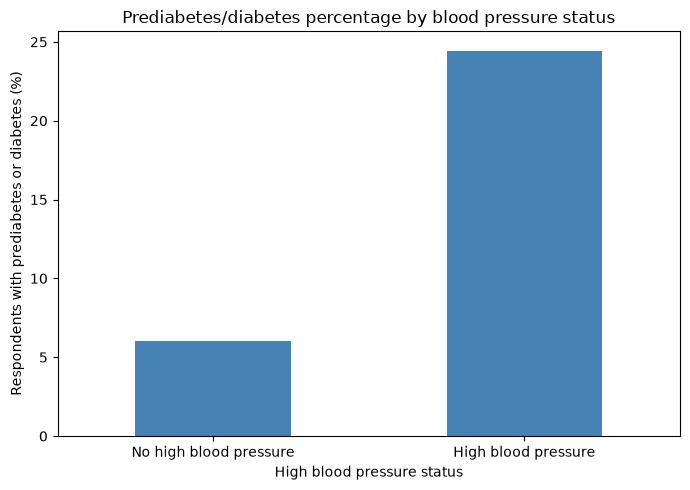

In [9]:
feature = "HighBP"

#Count respondents and calculate the class-1 percentage in each category
summary = df.groupby(feature)["Diabetes_binary"].agg(
    Respondents="size",
    Class_1_count="sum",
    Class_1_percent="mean"
)

summary["Class_1_percent"] *= 100

display(summary)

# Compare the class-1 percentages
summary["Class_1_percent"].plot(
    kind="bar",
    figsize=(7, 5),
    color="steelblue"
)

plt.xticks(
    [0, 1],
    ["No high blood pressure", "High blood pressure"],
    rotation=0
)
plt.xlabel("High blood pressure status")
plt.ylabel("Respondents with prediabetes or diabetes (%)")
plt.title("Prediabetes/diabetes percentage by blood pressure status")
plt.tight_layout()
plt.show()

Among respondents without high blood pressure, approximately 6.0% have prediabetes or diabetes, compared with 24.4% among respondents with high blood pressure. This difference of approximately 18.4 percentage points suggests an association between high blood pressure and the target outcome in this dataset. It does not establish causation.

***Lastly we want to look at how Age alters our results***

,Respondents,Class_1_percent
Age,,
18–24,5700,1.368421
25–29,7598,1.842590
30–34,11123,2.822979
35–39,13823,4.528684
40–44,16157,6.504920
45–49,19819,8.789545
50–54,26314,11.735198
55–59,30832,13.826544
60–64,33244,17.245217


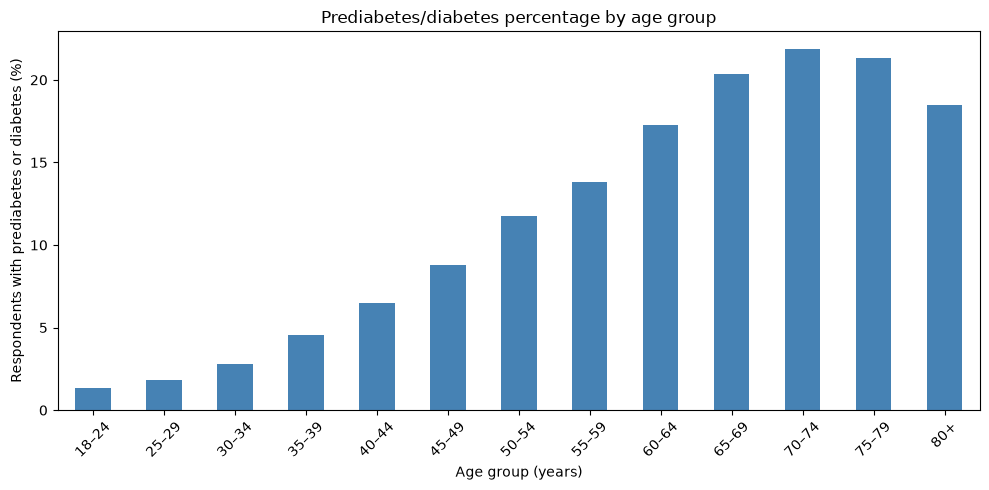

In [10]:
# Age codes represent ordered groups, not individual ages
age_labels = {    1: "18–24", 2: "25–29", 3: "30–34", 4: "35–39",    5: "40–44", 6: "45–49", 7: "50–54", 8: "55–59",    9: "60–64", 10: "65–69", 11: "70–74",    12: "75–79", 13: "80+"}

age_summary = df.groupby("Age")["Diabetes_binary"].agg(    Respondents="size",    Class_1_percent="mean")

age_summary["Class_1_percent"] *= 100
age_summary.index = age_summary.index.map(age_labels)

display(age_summary)

age_summary["Class_1_percent"].plot(    kind="bar",    figsize=(10, 5),    color="steelblue")

plt.xlabel("Age group (years)")
plt.ylabel("Respondents with prediabetes or diabetes (%)")
plt.title("Prediabetes/diabetes percentage by age group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The percentage of respondents with prediabetes or diabetes generally increases across age groups, reaching approximately 22% among those aged 70–74. It then decreases to approximately 20% for ages 75–79 and 18.48% for ages 80+. This suggests an association between age group and diabetes status in this dataset. These comparisons between respondents do not establish causation or show how an individual’s status changes as they age.

In [11]:
# Our other variables can be found as such. We will however not dive further into depth on these
remaining_features = [
    feature for feature in Binary_C + Cat_C
    if feature not in ["HighBP", "Age"]
]

for feature in remaining_features:

    summary = df.groupby(feature)["Diabetes_binary"].agg(
        Respondents="size",
        Class_1_count="sum",
        Class_1_percent="mean"
    )

    summary["Class_1_percent"] *= 100

    print(f"\nFeature: {feature}")
    display(summary.round(2))


Feature: HighChol


,Respondents,Class_1_count,Class_1_percent
HighChol,,,
0.0,146089,11660.0,7.98
1.0,107591,23686.0,22.01



Feature: CholCheck


,Respondents,Class_1_count,Class_1_percent
CholCheck,,,
0.0,9470,241.0,2.54
1.0,244210,35105.0,14.37



Feature: Smoker


,Respondents,Class_1_count,Class_1_percent
Smoker,,,
0.0,141257,17029.0,12.06
1.0,112423,18317.0,16.29



Feature: Stroke


,Respondents,Class_1_count,Class_1_percent
Stroke,,,
0.0,243388,32078.0,13.18
1.0,10292,3268.0,31.75



Feature: HeartDiseaseorAttack


,Respondents,Class_1_count,Class_1_percent
HeartDiseaseorAttack,,,
0.0,229787,27468.0,11.95
1.0,23893,7878.0,32.97



Feature: PhysActivity


,Respondents,Class_1_count,Class_1_percent
PhysActivity,,,
0.0,61760,13059.0,21.14
1.0,191920,22287.0,11.61



Feature: Fruits


,Respondents,Class_1_count,Class_1_percent
Fruits,,,
0.0,92782,14653.0,15.79
1.0,160898,20693.0,12.86



Feature: Veggies


,Respondents,Class_1_count,Class_1_percent
Veggies,,,
0.0,47839,8610.0,18.00
1.0,205841,26736.0,12.99



Feature: HvyAlcoholConsump


,Respondents,Class_1_count,Class_1_percent
HvyAlcoholConsump,,,
0.0,239424,34514.0,14.42
1.0,14256,832.0,5.84



Feature: AnyHealthcare


,Respondents,Class_1_count,Class_1_percent
AnyHealthcare,,,
0.0,12417,1422.0,11.45
1.0,241263,33924.0,14.06



Feature: NoDocbcCost


,Respondents,Class_1_count,Class_1_percent
NoDocbcCost,,,
0.0,232326,31604.0,13.60
1.0,21354,3742.0,17.52



Feature: DiffWalk


,Respondents,Class_1_count,Class_1_percent
DiffWalk,,,
0.0,211005,22225.0,10.53
1.0,42675,13121.0,30.75



Feature: Sex


,Respondents,Class_1_count,Class_1_percent
Sex,,,
0.0,141974,18411.0,12.97
1.0,111706,16935.0,15.16



Feature: Education


,Respondents,Class_1_count,Class_1_percent
Education,,,
1.0,174,47.0,27.01
2.0,4043,1183.0,29.26
3.0,9478,2296.0,24.22
4.0,62750,11066.0,17.64
5.0,69910,10354.0,14.81
6.0,107325,10400.0,9.69



Feature: Income


,Respondents,Class_1_count,Class_1_percent
Income,,,
1.0,9811,2383.0,24.29
2.0,11783,3086.0,26.19
3.0,15994,3568.0,22.31
4.0,20135,4054.0,20.13
5.0,25883,4504.0,17.40
6.0,36470,5291.0,14.51
7.0,43219,5265.0,12.18
8.0,90385,7195.0,7.96



Feature: GenHlth


,Respondents,Class_1_count,Class_1_percent
GenHlth,,,
1.0,45299,1140.0,2.52
2.0,89084,6381.0,7.16
3.0,75646,13457.0,17.79
4.0,31570,9790.0,31.01
5.0,12081,4578.0,37.89


Now we want to move on to our Logistical regression, we first create a Train and Test split
- We will be using a split of 80/20, meaning that 20% of the respondents are kept in reserve for the testing.
- radnom_state will be set to 42 to ensure that the random split is reproducible
- stratify=y keeps approximatly the same class proportion in the training segment, as the testing segment. to ensure that the test is logical.

In [12]:

X_train, X_test, y_train, y_test = train_test_split(    X,    y,   test_size=0.20,    random_state=42,    stratify=y)

print("TRAIN shape:", X_train.shape)
print("TEST shape:", X_test.shape)

# Compare class percentages across the datasets
class_balance = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "TRAIN (%)": y_train.value_counts(normalize=True) * 100,
    "TEST (%)": y_test.value_counts(normalize=True) * 100
}).sort_index()

display(class_balance.round(2))

TRAIN shape: (202944, 21)
TEST shape: (50736, 21)


,Full dataset (%),TRAIN (%),TEST (%)
Diabetes_binary,,,
0.0,86.07,86.07,86.07
1.0,13.93,13.93,13.93


We can see that we have a equal split of class 1 and 0 respondents

***we transoform variables to make sure that they are processed correctly***

In [13]:
preprocessor = ColumnTransformer(
    transformers=[    ("numerical", StandardScaler(), Numerical_C),    ("Categorical", "passthrough", Cat_C),    ("binary", "passthrough", Binary_C)])

# Before we connect our transformed variables to our model
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [14]:
#Before fitting the model
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['HighBP','HighChol','CholCheck',...,'Age','Education','Income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('Categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder=

Now we wan to predict our classes and probabilites for our test

Accuracy     0.8621
Precision    0.5173
Recall       0.1584
F1           0.2426
dtype: float64

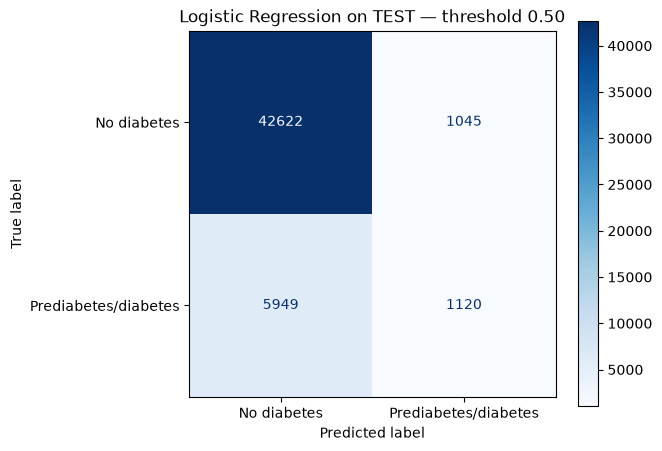

In [15]:
# Predict classes and probabilities for TEST
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate the required metrics
metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0)
})

display(metrics.round(4))

#Laslty we create a confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes", "Prediabetes/diabetes"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression on TEST — threshold 0.50")
plt.tight_layout()
plt.show()

The matrix shows
- True negatives -- false positives
- False negatives -- true positives

***findings***
- We can see that we have a accuracy of 86.21, only slightly above the 86.07 we would find if we predicted all ass class 0
- we have a low precission of 51.73, This means that only about half of the respondents predicted as class 1 actually belong to class 1
- our recall shows that we only identify about 16% of actuall class 1 respondents
- f1 reflects the combination of presision and low recall

***Now we want to see how our test responds to different thresholds***

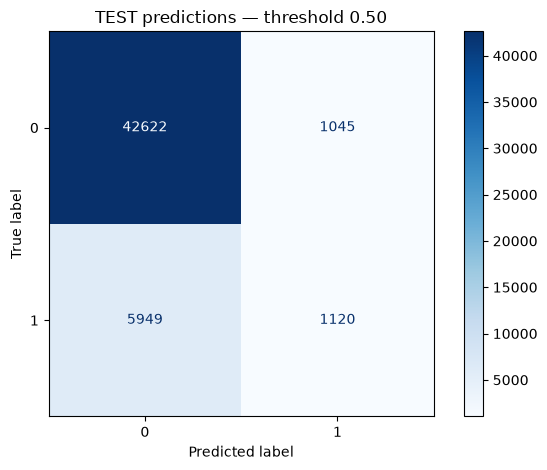

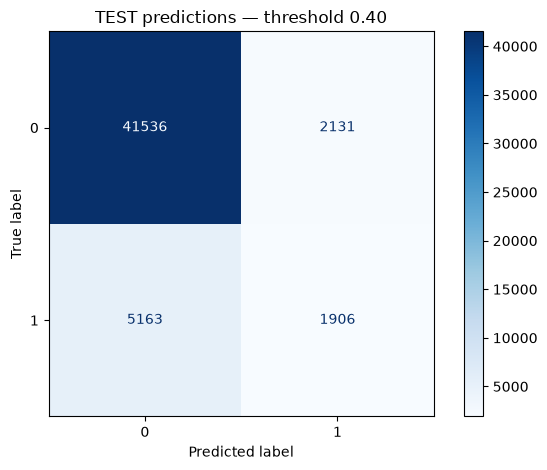

,Threshold,Accuracy,Precision,Recall,F1,False positives,False negatives
0,0.5,0.8621,0.5173,0.1584,0.2426,1045,5949
1,0.4,0.8562,0.4721,0.2696,0.3432,2131,5163


In [16]:
threshold_results = []

for threshold in [0.50, 0.40]:

    # Convert the same probabilities into classes
    predictions = (y_prob >= threshold).astype(int)

    # Extract the four confusion-matrix counts
    cm_threshold = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )
    tn, fp, fn, tp = cm_threshold.ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "False positives": fp,
        "False negatives": fn
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm_threshold,
        display_labels=[0, 1]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"TEST predictions — threshold {threshold:.2f}")
    plt.tight_layout()
    plt.show()

threshold_comparison = pd.DataFrame(threshold_results)
display(threshold_comparison.round(4))

***Findings***

Lowering the decision threshold from 0.50 to 0.40 increased recall from 15.84% to 26.96%. The model correctly identified 1,906 respondents with prediabetes or diabetes instead of 1,120, reducing false negatives from 5,949 to 5,163.

However, false positives increased from 1,045 to 2,131. Precision decreased from 51.73% to 47.21%, meaning a smaller proportion of positive predictions were correct. Accuracy also decreased from 86.21% to 85.62%, while F1 increased from 0.2426 to 0.3432.

This demonstrates a trade-off: the lower threshold identifies more actual class-1 respondents but incorrectly labels more class-0 respondents as positive. Neither threshold is universally better; the choice depends on the relative importance of missed cases and false positives. Even at 0.40, the model still misses most class-1 respondents.

The model was not retrained. Its fitted parameters, preprocessing, predicted probabilities, and TEST data remained unchanged. Only the rule converting probabilities into predicted classes changed: probabilities from 0.40 up to, but not including, 0.50 were now classified as class 1.

***Conclusion***
The EDA identified associations between diabetes status and features including BMI, physical health, high blood pressure, age group, and general health. These findings describe patterns in the dataset and do not establish causation.

Logistic Regression achieved 86.21% accuracy at threshold 0.50, but recall was only 15.84%. Its accuracy was only slightly above the approximately 86.07% obtained by always predicting class 0. This demonstrates why accuracy alone is insufficient for this imbalanced dataset.

Lowering the threshold to 0.40 increased recall to 26.96% and reduced false negatives, but increased false positives and reduced precision. The model therefore illustrates the trade-off between identifying more class-1 respondents and incorrectly classifying more class-0 respondents.

The analysis has several limitations:

- The data come from survey responses, which may contain reporting errors. The observed associations do not establish causal relationships.
- Retaining ordered category codes in Logistic Regression assumes an equal change in log-odds for each one-code increase. This may oversimplify relationships involving age, income, education, and general health.
- The target combines prediabetes and diabetes, so the model cannot distinguish between these conditions.